# **Bagging Regression on the Concrete Dataset**
Target: `strength` (concrete compressive strength, MPa)

**Bagging (Bootstrap Aggregating):**
1. Make many random copies of the training data (random rows picked *with replacement*).
2. Train one Decision Tree on each copy.
3. Final prediction = **average** of all trees.

One tree overfits and is unstable. Averaging many trees cancels their random errors, so the result is much more stable and accurate.

Hyperparameters tuned with `GridSearchCV` (5-fold, stratified):
- `n_estimators` : number of trees
- `max_samples` : fraction of rows each tree sees
- `max_features` : fraction of features each tree sees
- `estimator__max_depth` : depth limit of each tree

> Trees do not need feature scaling, so there is no `StandardScaler` here.

### Import

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Dataset and Stratified Split
High-strength samples are rare, so we split on strength ranges to keep the same ratio in train and test.

In [15]:
df = pd.read_csv('../1. Data_Preprocessing/For_Regression/concrete_after_preprocessing.csv')
x = df.drop('strength', axis=1)
y = df['strength']

#Strength ranges (used only for stratification)
bins = pd.cut(y, bins=[0, 20, 35, 50, 65, 100], labels=False)

x_train, x_test, y_train, y_test, bins_train, _ = train_test_split(
    x, y, bins, test_size=0.2, random_state=42, stratify=bins)
print(x_train.shape, x_test.shape)

#Stratified 5-fold CV
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_train, bins_train))

(804, 8) (201, 8)


### Bagging Model and Hyperparameter Grid

In [16]:
bagging = BaggingRegressor(
    estimator=DecisionTreeRegressor(random_state=42),   # base model = Decision Tree
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_samples': [0.6, 0.8, 1.0],
    'max_features': [0.6, 0.8, 1.0],
    'estimator__max_depth': [None, 10],
}

### GridSearchCV

In [17]:
%%time
grid = GridSearchCV(bagging, param_grid, cv=cv, scoring='r2', n_jobs=1, return_train_score=True)
grid.fit(x_train, y_train)

print('Best Params      :', grid.best_params_)
print('Best CV R2 score :', round(grid.best_score_, 4))
print('Train R2 score   :', round(grid.cv_results_['mean_train_score'][grid.best_index_], 4))

Best Params      : {'estimator__max_depth': None, 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 200}
Best CV R2 score : 0.9032
Train R2 score   : 0.9842
CPU times: total: 1min 39s
Wall time: 3min 20s


### Test Set Evaluation

In [18]:
best_bag = grid.best_estimator_
y_pred = best_bag.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE  :', round(mae, 4))
print('MSE  :', round(mse, 4))
print('RMSE :', round(rmse, 4))
print('R2   :', round(r2, 4))

MAE  : 3.7111
MSE  : 32.6937
RMSE : 5.7178
R2   : 0.8779


### Why bagging helps: single tree vs bagging

In [19]:
single_tree = DecisionTreeRegressor(random_state=42).fit(x_train, y_train)

compare = pd.DataFrame({
    'Single Tree': [single_tree.score(x_train, y_train), single_tree.score(x_test, y_test),
                    mean_absolute_error(y_test, single_tree.predict(x_test))],
    'Bagging':     [best_bag.score(x_train, y_train), best_bag.score(x_test, y_test), mae],
}, index=['Train R2', 'Test R2', 'Test MAE'])
compare.round(4)

,Single Tree,Bagging
Train R2,0.9974,0.9859
Test R2,0.7308,0.8779
Test MAE,5.0560,3.7111


### Visualization

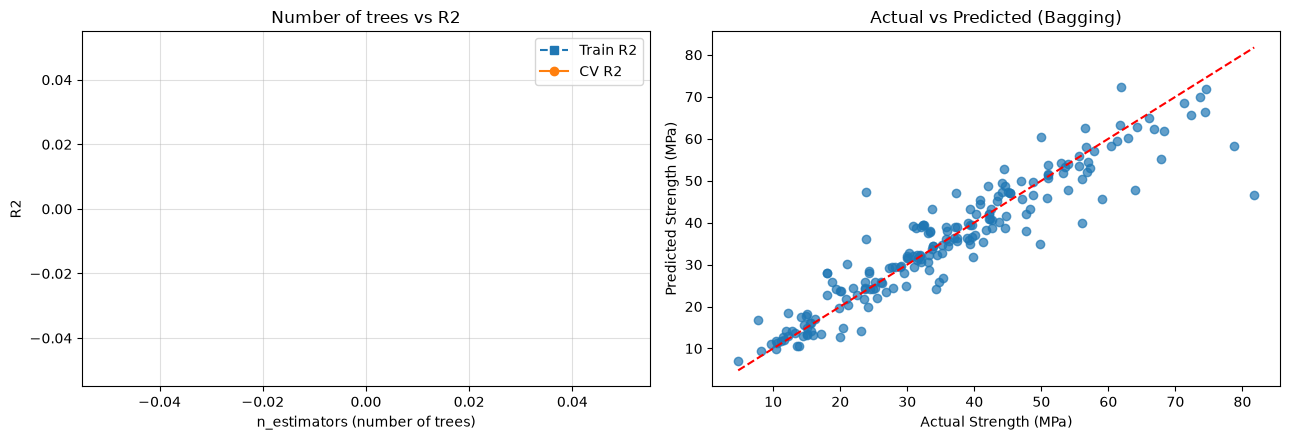

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

#Number of trees vs R2 (other params = best)
res = pd.DataFrame(grid.cv_results_)
mask = np.ones(len(res), dtype=bool)
for p in ['max_samples', 'max_features', 'estimator__max_depth']:
    mask &= (res['param_' + p].astype(str) == str(grid.best_params_[p]))
r = res[mask].sort_values('param_n_estimators')

ax[0].plot(r['param_n_estimators'].astype(int), r['mean_train_score'], 's--', label='Train R2')
ax[0].plot(r['param_n_estimators'].astype(int), r['mean_test_score'], 'o-', label='CV R2')
ax[0].set_xlabel('n_estimators (number of trees)'); ax[0].set_ylabel('R2')
ax[0].set_title('Number of trees vs R2'); ax[0].legend(); ax[0].grid(alpha=0.4)

#Actual vs Predicted
ax[1].scatter(y_test, y_pred, alpha=0.7)
ax[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[1].set_xlabel('Actual Strength (MPa)'); ax[1].set_ylabel('Predicted Strength (MPa)')
ax[1].set_title('Actual vs Predicted (Bagging)')

plt.tight_layout(); plt.show()

### Save the Model (.pkl)
Best Bagging model is trained once more on all data, then saved with `joblib`.

In [21]:
from sklearn.base import clone

final_bag = clone(best_bag)
final_bag.fit(x, y)

joblib.dump(final_bag, 'bagging_concrete_model.pkl', compress=3)    # compress = smaller file
print('Saved: bagging_concrete_model.pkl')

Saved: bagging_concrete_model.pkl


### Load and Predict
These 5 rows were also used to train the final model, so predictions look better than reality. This cell only checks that the saved file loads and works. The honest accuracy is the **Test Set Evaluation** above (trained without the test rows).

In [22]:
model = joblib.load('bagging_concrete_model.pkl')

new_rows = x_test.iloc[:5]
print('Predicted strength:', model.predict(new_rows).round(2))
print('Actual strength   :', y_test.iloc[:5].round(2).values)

Predicted strength: [22.75 14.44 18.58 30.21 67.31]
Actual strength   : [21.97 15.07 18.03 30.23 68.3 ]


### Download (Google Colab only)

In [23]:
try:
    from google.colab import files
    files.download('bagging_concrete_model.pkl')
except ImportError:
    print('Not Colab - file is saved in the notebook folder.')

Not Colab - file is saved in the notebook folder.
